# Détection et anonymisation des données personnelles dans les textes
**Auteur:** Sarra Lamouchi





## Introduction + problématique

### Contexte
Les textes en langue naturelle peuvent contenir différentes catégories de données à caractère personnel (PII – Personally Identifiable Information), telles que les noms, les adresses, les coordonnées téléphoniques, les adresses électroniques ou encore les informations bancaires.

La détection automatique de ces informations constitue une étape importante dans les processus de protection et d'anonymisation des données. Elle permet notamment d'identifier les informations sensibles présentes dans un texte avant leur traitement, leur partage ou leur réutilisation.

### Problématique

Comment détecter automatiquement les informations personnelles présentes dans des textes français et les anonymiser de manière fiable, tout en prenant en compte les différences entre les PII structurées et les PII dépendantes du contexte ?

### Objectifs
Développer et évaluer une solution de détection et d'anonymisation automatique des PII.





### Pipeline

 Texte original --> span_labels(début, fin, catégorie) --> Tokenizer CamemBERT -->  Tokens --> offset_mapping (start, end)--> ALIGNEMENT
 (le passage span_labels à labels BIO) --> Labels BIO (Beginning,Inside, Outside)  -->  Fine-tuning NER --> prédiction --> Reconstruction --> Anonymisation

 ### Dataset 
 Le jeu de données utilisé dans ce projet est **https://huggingface.co/datasets/TypicaAI/pii-masking-60k_fr**, disponible sur la plateforme **Hugging Face**.
                    

### État de l'art

La littérature sur la détection et l’anonymisation des données personnelles distingue généralement **les PII structurées**, pouvant être identifiées à partir de formats réguliers, **des PII dépendantes du contexte**, nécessitant une analyse linguistique. Les approches à base de règles sont particulièrement adaptées aux formats rigides, tandis que les modèles NLP permettent de mieux traiter les informations variables et contextuelles.

Les travaux récents mettent également en évidence l'intérêt **des approches hybrides**, combinant des règles déterministes avec des modèles de reconnaissance d'entités. Par ailleurs, les méthodes basées uniquement sur des règles peuvent être sensibles aux formats spécifiques du jeu de données et présenter des limites de généralisation.

Dans ce contexte, **notre approche combine une baseline Regex avec un modèle CamemBERT fine-tuné** pour la reconnaissance d'entités PII, puis exploite leurs prédictions dans une approche hybride.



| Axe | Constat de la littérature | Lien avec le pipeline |
|---|---|---|
| **Taxonomie structuré vs. non-structuré** | RECAP (Rajgarhia et al., 2025) distingue les PII à format syntaxique régulier (checksum-vérifiable) des PII sémantiquement variables, et recommande une architecture combinant règles + LLM/modèle contextuel | Logique découverte empiriquement : EMAIL/CRYPTO/NATIONAL_ID en regex, CREDENTIAL/DATE en CamemBERT |
| **Limite de généralisation des règles** | Lison & Pilán (2021, 2022 — TAB) et l'étude *crash narratives* (2026) : les règles dépendent d'indices spécifiques au dataset, peu transférables — F1 ~81% au niveau token sur documents financiers | Justifie la mise en garde sur `\d{8}`/`\d{11}`, sur-ajustés au dataset Faker synthétique |
| **Formats rigides vs. flexibles** | *Mind the Gap* (2025) : les formats rigides (SSN, IP) restent fiables en regex simple ; les formats semi-rigides à flexibles (téléphone, date) plafonnent structurellement, quelle que soit la sophistication de la regex | Explique l'abandon de `phonenumbers`/`dateparser` au profit de regex ciblées sur les formats réellement observés |
| **Modèles zero-shot génériques** | GLiNER2-PII (Zaratiana et al., 2026) : 300M paramètres, 42 types d'entités prêts à l'emploi, adaptable sans réentraînement | Contrepoint justifiant le choix de CamemBERT fine-tuné (contrôle total, léger) plutôt qu'un modèle zero-shot |
| **Pipeline hybride chiffré** | Scientific Reports/Nature (2025), documents financiers : precision 94.7%, recall 89.4%, F1 91.1% (règles+ML+NER) ; souligne le trade-off persistant recall/précision | Référence chiffrée comparable au F1 macro du projet (~0.81 regex, ~0.93 CamemBERT) |


In [ ]:
# Verification de l'environnement 
import os, sys, platform
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")   # Windows : evite l'avertissement de symlinks du cache HF
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")        # evite un warning de fork avec les tokenizers rapides

import torch, transformers, datasets, pandas, sklearn

print("Python       :", sys.version.split()[0], "|", platform.system())
print("Dossier      :", os.getcwd(), "-> cache_finetune/, runs/ et pii_project_backup/ seront crees ici")
print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("datasets     :", datasets.__version__)
print("pandas       :", pandas.__version__, "| scikit-learn :", sklearn.__version__)

if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    print("GPU          : Apple MPS")
else:
    print("GPU          : AUCUN -> le fine-tuning (5 seeds x 5 epochs) sera tres lent sur CPU")


Python       : 3.13.2 | Windows
Dossier      : c:\Users\USER\Documents\PII and text Anonymization -> cache_finetune/, runs/ et pii_project_backup/ seront crees ici
torch        : 2.14.0+cu130
transformers : 5.17.0
datasets     : 5.0.1
pandas       : 3.0.6 | scikit-learn : 1.9.1
GPU          : NVIDIA GeForce RTX 4050 Laptop GPU


## Setup

In [2]:
import ast, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset, Dataset, DatasetDict

SEED = 42
random.seed(SEED)
np.random.seed(SEED)


## Chargement de dataset  

**Correction des types :**

`privacy_mask` et `span_labels` sont stockés comme des chaînes de texte (`str`) dans
ce dataset — un artefact de la conversion Parquet détecté précédemment.

`bio_labels` et
`tokenised_text` sont déjà de vrais `numpy.ndarray`, mais alignés sur un tokenizer différent
de CamemBERT — on ne les réutilise pas, on repart de `span_labels`.

**Comment on passe d'un texte annoté au niveau des caractères à un texte annoté au niveau des tokens, afin d'entraîner CamemBERT pour une tâche de NER.**

In [3]:
#Chargement de dataset
raw_fr = load_dataset("TypicaAI/pii-masking-60k_fr")
df_fr = raw_fr["train"].to_pandas()
print("Taille totale :", len(df_fr))

df_fr['span_labels'] = df_fr['span_labels'].apply(ast.literal_eval)
df_fr['privacy_mask'] = df_fr['privacy_mask'].apply(ast.literal_eval)
print("Parsing OK.")


Taille totale : 61918
Parsing OK.


In [4]:
# Nettoyage et structuration des annotations PII au niveau des caractères.
# Les labels contenant un suffixe numérique (ex. PREFIX_1, PREFIX_2) sont ramenés à leur catégorie générale (PREFIX).
# Les segments associés au label "O" sont ignorés car ils ne correspondent pas à des entités PII.
# Les annotations sont ensuite converties sous la forme :{start, end, label}, puis stockées dans une nouvelle colonne "entities"

def strip_instance_suffix(label):
    """'PREFIX_1' -> 'PREFIX' ; 'O' reste 'O'."""
    if label == "O":
        return "O"
    return re.sub(r'_\d+$', '', label)


def build_entities_from_span_labels(span_labels):
    """Convertit [[start, end, 'LABEL_N'], ...] en liste de dicts
    {start, end, label} propres, en ignorant les segments 'O'."""
    entities = []
    for start, end, label in span_labels:
        if label == "O":
            continue
        entities.append({"start": start, "end": end, "label": strip_instance_suffix(label)})
    return entities

df_fr['entities'] = df_fr['span_labels'].apply(build_entities_from_span_labels)
print(df_fr.iloc[0]['entities'])


[{'start': 5, 'end': 8, 'label': 'PREFIX'}, {'start': 9, 'end': 16, 'label': 'LASTNAME'}, {'start': 67, 'end': 78, 'label': 'CITY'}, {'start': 101, 'end': 120, 'label': 'COMPANYNAME'}, {'start': 132, 'end': 149, 'label': 'EMAIL'}]


**Résultat:** Cette sortie constitue donc **une représentation propre des entités PII au niveau des caractères**, qui sera ensuite utilisée pour l'étape d'alignement avec les tokens de CamemBERT via offset_mapping.

## EDA

Distribution des 56 catégories fines, longueur des textes, densité
d'entités par exemple. Cette analyse a déjà été validée — elle sert ici de référence pour
vérifier les effectifs des nouvelles sous-catégories (`BANK_ID`, `CRYPTO_ADDRESS`, `NATIONAL_ID`,
`CREDENTIAL`) avant de les regrouper.

In [5]:
df_fr['n_entities'] = df_fr['entities'].apply(len)
df_fr['text_len_chars'] = df_fr['unmasked_text'].str.len()

all_labels = df_fr['entities'].apply(lambda ents: [e['label'] for e in ents]).sum()
label_counts = Counter(all_labels)

print("Nombre de categories PII distinctes :", len(label_counts))
print("Nombre moyen d'entites par exemple :", df_fr['n_entities'].mean().round(2))


Nombre de categories PII distinctes : 56
Nombre moyen d'entites par exemple : 3.09


**Résultat:** Cette cellule permet de caractériser la complexité des annotations PII : le dataset contient **56 catégories PII** distinctes et chaque texte contient **en moyenne 3,09 entités**. Ces informations sont importantes pour comprendre la diversité des classes et la densité des annotations avant l'entraînement du modèle NER.

In [6]:
# Verification specifique des effectifs des sous-categories concernees par le nouveau decoupage.
# condition pour valider que la separation reste viable (volume suffisant par nouvelle categorie apres sampling stratifie)

categories_of_interest = ["IBAN", "BIC", "CREDITCARDNUMBER", "CREDITCARDCVV",
                           "CREDITCARDISSUER", "MASKEDNUMBER", "ACCOUNTNUMBER",
                           "BITCOINADDRESS", "ETHEREUMADDRESS", "LITECOINADDRESS",
                           "SSN", "PASSWORD", "PIN", "ACCOUNTNAME", "USERNAME"]

for cat in categories_of_interest:
    print(f"{cat:20s} {label_counts.get(cat, 0)}")


IBAN                 3004
BIC                  1040
CREDITCARDNUMBER     3876
CREDITCARDCVV        1218
CREDITCARDISSUER     2017
MASKEDNUMBER         3300
ACCOUNTNUMBER        3488
BITCOINADDRESS       3408
ETHEREUMADDRESS      2150
LITECOINADDRESS      1110
SSN                  3334
PASSWORD             3804
PIN                  999
ACCOUNTNAME          3564
USERNAME             3502


**Résultat:** L’objectif est de vérifier que chaque nouvelle catégorie possède un nombre suffisant d’exemples pour rester exploitable après le sampling stratifié.

## Réduction des catégories

**Changement principal :**

l'ancienne catégorie `ID_NUMBER` est éclatée en 4 catégories plus
logiques, séparant explicitement le structuré (détectable par regex) du non-structuré .

Les autres groupes (`NAME`, `EMAIL`, `PHONE`, `ADDRESS`, `DATE`,
`DEMOGRAPHIC`, `FINANCIAL`, `ORG`, `DIGITAL_ID`) restent inchangés — validés à l'EDA précédente.

In [7]:
# Regroupement des catégories PII fines en catégories parentes.Chaque catégorie fine est associée à une catégorie générale selon sa nature

CATEGORY_GROUPS = {
    "NAME": ["FIRSTNAME", "LASTNAME", "MIDDLENAME", "PREFIX"],
    "EMAIL": ["EMAIL"],
    "PHONE": ["PHONENUMBER", "PHONEIMEI"],
    "ADDRESS": ["STREET", "CITY", "STATE", "ZIPCODE", "BUILDINGNUMBER",
                "SECONDARYADDRESS", "COUNTY", "NEARBYGPSCOORDINATE"],
    "DATE": ["DATE", "DOB", "TIME"],
    "DEMOGRAPHIC": ["SEX", "GENDER", "AGE", "JOBTYPE", "JOBTITLE", "EYECOLOR", "HEIGHT"],
    "FINANCIAL": ["AMOUNT", "CURRENCYSYMBOL", "CURRENCY", "CURRENCYCODE", "CURRENCYNAME"],
    "ORG": ["COMPANYNAME", "JOBAREA"],
    "DIGITAL_ID": ["IP", "IPV4", "IPV6", "MAC", "USERAGENT", "URL"],

    # Identifiants bancaires structures : format syntaxique fixe + une vraie somme de controle mathematique (IBAN -> mod-97, carte -> Luhn)
    # entierement detectables par une regex bien concue.

    "BANK_ID": ["IBAN", "BIC", "CREDITCARDNUMBER", "CREDITCARDCVV",
                "CREDITCARDISSUER", "MASKEDNUMBER", "ACCOUNTNUMBER"],

    # Adresses crypto : chacune a un format tres specifique et documente (prefixes/longueurs fixes) - egalement bien detectable par regex.
    "CRYPTO_ADDRESS": ["BITCOINADDRESS", "ETHEREUMADDRESS", "LITECOINADDRESS"],

    # Identifiant national : format variable selon la convention du pays, detection partielle possible.
    "NATIONAL_ID": ["SSN"],

    # Identifiants d'authentification : AUCUN format syntaxique fixe par nature (un mot de passe peut etre n'importe quelle chaine)

    "CREDENTIAL": ["PASSWORD", "PIN", "ACCOUNTNAME", "USERNAME"],
}
DEFAULT_CATEGORY = "MISC"

CATEGORY_MAPPING = {fine: parent for parent, fines in CATEGORY_GROUPS.items() for fine in fines}

present_categories = set(label_counts.keys())
mapped = present_categories & set(CATEGORY_MAPPING.keys())
unmapped = present_categories - set(CATEGORY_MAPPING.keys())
print(f"Categories mappees : {len(mapped)} / {len(present_categories)}")
print(f"Categories non mappees (-> MISC) : {sorted(unmapped)}")
print(f"Nombre de categories parentes finales : {len(set(CATEGORY_MAPPING.values())) + 1} (incluant MISC)")


Categories mappees : 53 / 56
Categories non mappees (-> MISC) : ['ORDINALDIRECTION', 'VEHICLEVIN', 'VEHICLEVRM']
Nombre de categories parentes finales : 14 (incluant MISC)


**Résultat:** Dans cette étape, je regroupe les catégories PII fines en catégories parentes afin de réduire la complexité du problème.

 Par exemple, **FIRSTNAME, LASTNAME, MIDDLENAME** et **PREFIX** sont regroupées dans **NAME**, tandis que les différentes **informations bancaires** sont regroupées dans **BANK_ID**.

 **Sur les 56 catégories initiales, 53 sont correctement mappées**.

 Trois catégories — **ORDINALDIRECTION, VEHICLEVIN et VEHICLEVRM** — ne disposent pas de correspondance et sont donc orientées vers MISC.

 Au final, **le regroupement permet de passer à 14 catégories parentes**



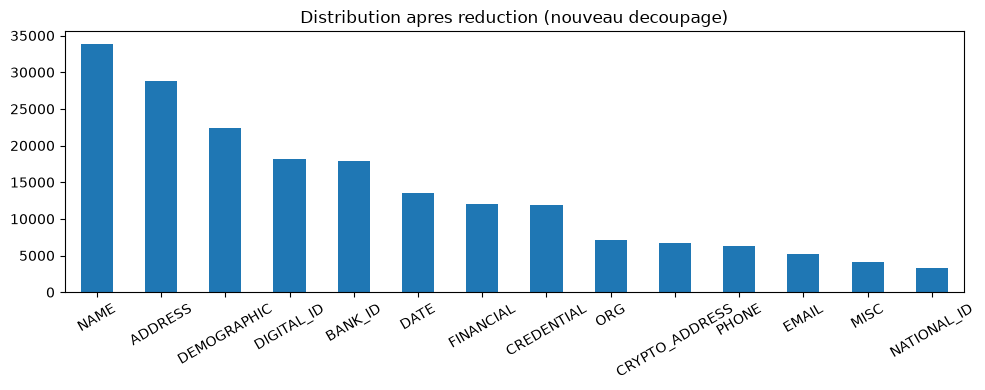

In [8]:
def remap_entities(entities):
    remapped = []
    for ent in entities:
        new_label = CATEGORY_MAPPING.get(ent['label'], DEFAULT_CATEGORY)
        remapped.append({'start': ent['start'], 'end': ent['end'], 'label': new_label})
    return remapped

df_fr['entities_reduced'] = df_fr['entities'].apply(remap_entities)

reduced_labels = df_fr['entities_reduced'].apply(lambda ents: [e['label'] for e in ents]).sum()
pd.Series(Counter(reduced_labels)).sort_values(ascending=False).plot(
    kind='bar', figsize=(10, 4), title="Distribution apres reduction (nouveau decoupage)"
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Résultat:**

Après le nouveau regroupement, on observe une distribution assez hétérogène entre les catégories.

Les catégories **NAME, ADDRESS et DEMOGRAPHIC** sont **les plus représentées**, tandis que **NATIONAL_ID, MISC et EMAIL** sont **moins fréquentes**.

**Le regroupement permet donc de réduire la complexité du problème**, mais il ne supprime pas complètement le déséquilibre entre les classes.

 Ce point devra être pris en compte lors de l'entraînement et surtout lors de l'évaluation du modèle NER.

## Correction des entités FINANCIAL (bruit d'annotation)

l'inspection manuelle a révélé une incohérence d'annotation, le montant numérique
associé à un **code/symbole** devise est parfois annoté comme une seule entité, parfois omis
(*Missing Error*, Wang et al. 2023).

In [9]:
def extend_financial_entities(text, entities):
    extended = []
    for ent in entities:
        new_end = ent['end']
        if ent['label'] == "FINANCIAL":
            match = re.match(r'\s?(\d[\d.,]*)', text[ent['end']:])
            if match:
                candidate_end = ent['end'] + match.end()
                blocking_other_label = False
                for other in entities:
                    if (other['start'], other['end']) == (ent['start'], ent['end']):
                        continue
                    overlap = other['start'] < candidate_end and other['end'] > ent['end']
                    if overlap and other['label'] != "FINANCIAL":
                        blocking_other_label = True
                if not blocking_other_label:
                    new_end = candidate_end
        extended.append({'start': ent['start'], 'end': new_end, 'label': ent['label']})

    extended = sorted(extended, key=lambda e: e['start'])
    merged = []
    for ent in extended:
        if merged and merged[-1]['label'] == ent['label'] and ent['start'] <= merged[-1]['end']:
            merged[-1]['end'] = max(merged[-1]['end'], ent['end'])
        else:
            merged.append(dict(ent))
    return merged


# Tests de non-regression sur les 2 cas qui avaient revele des bugs
test_gnf_text = "Le compte 1YMV3xn183WwCqwMAMRo7SGhP7W4Vsetk n\u00e9cessite une mise \u00e0 jour du solde conform\u00e9ment au GNF. Le client Roman Barrows demande des documents."
test_gnf_entities = [{'start': 95, 'end': 98, 'label': 'FINANCIAL'}]
print("GNF :", extend_financial_entities(test_gnf_text, test_gnf_entities))  # attendu: end=98

test_nzd_text = "Le montant total de votre consultation et de vos conseils en m\u00e9decine alternative est de New Zealand Dollar492398.88."
test_nzd_entities = [{'start': 89, 'end': 107, 'label': 'FINANCIAL'}, {'start': 107, 'end': 117, 'label': 'FINANCIAL'}]
print("NZD :", extend_financial_entities(test_nzd_text, test_nzd_entities))  # attendu: 1 entite {89,117}


GNF : [{'start': 95, 'end': 98, 'label': 'FINANCIAL'}]
NZD : [{'start': 89, 'end': 117, 'label': 'FINANCIAL'}]


**Résultat:** Cette fonction permet de corriger les annotations financières après la détection.

Elle vérifie d'abord si une entité **FINANCIAL** peut être étendue lorsqu'un montant numérique se trouve juste après.


In [10]:
# Application sur df_fr entier (avant le split, pour que la correction soit visible dans l'EDA et coherente pour tout le pipeline en aval)

df_fr['entities_reduced'] = df_fr.apply(
    lambda row: extend_financial_entities(row['unmasked_text'], row['entities_reduced']), axis=1
)
print("Correction FINANCIAL appliquee sur tout df_fr.")


Correction FINANCIAL appliquee sur tout df_fr.


## Sous-échantillonnage stratifié + split train/val/test + anti-fuite

Reprise à l'identique de la méthodologie déjà validée : stratification sur la catégorie PII
dominante, sampling proportionnel à 8000 exemples, split 70%/15%/15%, vérification anti-fuite sur
les textes masqués.

In [11]:
def dominant_category(entities):
    if not entities:
        return "NONE"
    labels = [e['label'] for e in entities]
    return Counter(labels).most_common(1)[0][0]

df_fr['dominant_cat'] = df_fr['entities_reduced'].apply(dominant_category)
print(df_fr['dominant_cat'].value_counts())


dominant_cat
NAME              18537
ADDRESS            9801
DEMOGRAPHIC        9024
BANK_ID            4711
DIGITAL_ID         4445
CREDENTIAL         3466
DATE               2757
FINANCIAL          2387
ORG                2107
CRYPTO_ADDRESS     1522
MISC               1443
NATIONAL_ID         795
PHONE               521
EMAIL               402
Name: count, dtype: int64


**Résultat:** La distribution des catégories dominantes montre une forte présence de **NAME (18 537), ADDRESS (9 801) et DEMOGRAPHIC (9 024), tandis que EMAIL (402), PHONE (521) et NATIONAL_ID (795)** sont **les catégories les moins représentées**, révélant ainsi **un déséquilibre** entre les différents types de PII dans le corpus.

In [12]:
TARGET_SIZE = 8000
# Compatible pandas 2.x ET 3.x : en pandas 3, groupby().apply() exclut la colonne de groupement
# ('dominant_cat' disparaitrait). On echantillonne groupe par groupe puis on concatene :
# meme resultat qu'avant (meme ordre de groupes, meme random_state).
df_sampled = pd.concat(
    [g.sample(n=min(len(g), max(1, round(TARGET_SIZE * len(g) / len(df_fr)))), random_state=SEED)
     for _, g in df_fr.groupby('dominant_cat')]
).reset_index(drop=True)
print("Taille echantillonnee :", len(df_sampled))
print(df_sampled['dominant_cat'].value_counts())


Taille echantillonnee : 7999
dominant_cat
NAME              2395
ADDRESS           1266
DEMOGRAPHIC       1166
BANK_ID            609
DIGITAL_ID         574
CREDENTIAL         448
DATE               356
FINANCIAL          308
ORG                272
CRYPTO_ADDRESS     197
MISC               186
NATIONAL_ID        103
PHONE               67
EMAIL               52
Name: count, dtype: int64


**Résultat :**  L’échantillon obtenu contient 7 999 textes, avec **une distribution proportionnelle** aux catégories initiales : **NAME (2 395), ADDRESS (1 266) et DEMOGRAPHIC (1 166) restent majoritaires**, tandis que **EMAIL (52) et PHONE (67)** sont **les catégories les moins représentées**, ce qui conserve le déséquilibre initial du corpus.

In [ ]:
# eviter la fuite de data 
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df_sampled, test_size=0.3, stratify=df_sampled['dominant_cat'], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['dominant_cat'], random_state=SEED
)

overlap = set(train_df['masked_text']) & set(test_df['masked_text'])
if overlap:
    test_df = test_df[~test_df['masked_text'].isin(overlap)]
    print(f"{len(overlap)} doublons retires du test set.")

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")


17 doublons retires du test set.
Train: 5599 | Val: 1200 | Test: 1183


## Tokenisation CamemBERT et alignement via `offset_mapping`

Méthode inchangée (positions caractères, indépendantes du tokenizer d'origine du dataset) — seule
la liste des labels change pour refléter le nouveau découpage (`BANK_ID`, `CRYPTO_ADDRESS`,
`NATIONAL_ID`, `CREDENTIAL` remplacent `ID_NUMBER`).

In [14]:
from transformers import AutoTokenizer

MODEL_NAME = "camembert-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

categories = sorted(set(CATEGORY_MAPPING.values()) | {DEFAULT_CATEGORY})
label_list = ["O"] + [f"{p}-{c}" for c in categories for p in ("B", "I")]
label2id = {l: i for i, l in enumerate(label_list)}
id2label = {i: l for l, i in label2id.items()}
print(f"Nombre de labels : {len(label_list)}")


Nombre de labels : 29


In [15]:
def tokenize_and_align_labels(example):
    tokenized = tokenizer(
        example["unmasked_text"], truncation=True, max_length=128,
        return_offsets_mapping=True,
    )
    offsets = tokenized.pop("offset_mapping")
    entities = example["entities_reduced"]

    labels = []
    current_entity_idx = None
    for (start, end) in offsets:
        if start == end:
            labels.append(-100)
            current_entity_idx = None
            continue
        matched_label = "O"
        matched_idx = None
        for idx, ent in enumerate(entities):
            if start < ent["end"] and end > ent["start"]:
                matched_idx = idx
                prefix = "B" if current_entity_idx != idx else "I"
                matched_label = f"{prefix}-{ent['label']}"
                break
        labels.append(label2id.get(matched_label, label2id["O"]))
        current_entity_idx = matched_idx

    tokenized["labels"] = labels
    return tokenized


hf_train = Dataset.from_pandas(train_df[["unmasked_text", "entities_reduced"]])
hf_val   = Dataset.from_pandas(val_df[["unmasked_text", "entities_reduced"]])
hf_test  = Dataset.from_pandas(test_df[["unmasked_text", "entities_reduced"]])

dataset_tok = DatasetDict({
    "train": hf_train.map(tokenize_and_align_labels, remove_columns=hf_train.column_names),
    "validation": hf_val.map(tokenize_and_align_labels, remove_columns=hf_val.column_names),
    "test": hf_test.map(tokenize_and_align_labels, remove_columns=hf_test.column_names),
})
dataset_tok


Map:   0%|          | 0/5599 [00:00<?, ? examples/s]

Map:   0%|          | 0/1200 [00:00<?, ? examples/s]

Map:   0%|          | 0/1183 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 5599
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1200
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1183
    })
})

La tokenisation et l’alignement des labels ont été effectués avec succès

In [16]:
# Verification visuelle de l'alignement sur le premier exemple du train
sample = dataset_tok["train"][0]
tokens = tokenizer.convert_ids_to_tokens(sample["input_ids"])
labels_readable = [id2label[l] if l != -100 else "-100" for l in sample["labels"]]
for tok, lab in zip(tokens, labels_readable):
    print(f"{tok:15s} -> {lab}")


<s>             -> -100
▁Hier           -> O
,               -> O
▁nous           -> O
▁avons          -> O
▁eu             -> O
▁une            -> O
▁discussion     -> O
▁enrichissante  -> O
▁sur            -> O
▁le             -> O
▁rôle           -> O
▁que            -> O
▁le             -> O
▁genre          -> O
▁(              -> O
Trans           -> B-DEMOGRAPHIC
g               -> I-DEMOGRAPHIC
ender           -> I-DEMOGRAPHIC
▁person         -> I-DEMOGRAPHIC
▁vs             -> O
▁Trans          -> B-DEMOGRAPHIC
g               -> I-DEMOGRAPHIC
ender           -> I-DEMOGRAPHIC
▁fe             -> I-DEMOGRAPHIC
male            -> I-DEMOGRAPHIC
)               -> O
▁peut           -> O
▁jouer          -> O
▁dans           -> O
▁l              -> O
'               -> O
apprentissage   -> O
▁socio          -> O
-               -> O
émotion         -> O
nel             -> O
.               -> O
▁La             -> O
▁vidéo          -> O
▁de             -> O
▁la             -> O
▁réunio

La vérification montre que l’alignement est cohérent.

**Technique :** vérification visuelle de l’alignement token–label après tokenisation, selon le schéma **BIO (B-, I-, O)**, avec **-100** pour les **tokens spéciaux ignorés**.(schéma d'annotation)

**Résultat :** sur le premier exemple, 2 entités DEMOGRAPHIC sont correctement détectées, composées de plusieurs sous-tokens (B-DEMOGRAPHIC puis I-DEMOGRAPHIC), tandis que les autres tokens sont classés O.

In [17]:
# ============================================================
# CACHE du dataset tokenise (pour reprendre le fine-tuning apres un
# redemarrage du runtime SANS relancer tout le pretraitement)
# ============================================================
# Pourquoi : un redemarrage efface toutes les variables en memoire
# (dataset_tok, label_list...). Ce cache permet a la section fine-tuning
# de se recharger seule. Le split est deterministe (SEED=42), donc le
# cache correspond exactement aux memes train/val/test.
import os, json
CACHE_DIR = "./cache_finetune"
os.makedirs(CACHE_DIR, exist_ok=True)
dataset_tok.save_to_disk(f"{CACHE_DIR}/dataset_tok")
with open(f"{CACHE_DIR}/label_list.json", "w") as f:
    json.dump(label_list, f)
print("Cache ecrit dans", CACHE_DIR)


Saving the dataset (0/1 shards):   0%|          | 0/5599 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1200 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/1183 [00:00<?, ? examples/s]

Cache ecrit dans ./cache_finetune


## Baseline Regex




**Principe :** la baseline Regex repose sur des expressions régulières permettant de rechercher dans les textes des motifs correspondant à différentes catégories de PII (emails, téléphones, dates, identifiants bancaires, etc.). Les détections sont ensuite validées et filtrées, puis les chevauchements sont résolus.

In [18]:
# --- Patterns simples et independants par categorie ---
EMAIL_PATTERN = r"[\w.+-]+@[\w-]+\.[a-zA-Z]{2,}"

REGEX_PATTERNS = {"EMAIL": EMAIL_PATTERN}

# --- BANK_ID : 4 sous-types couverts (le 5e, CVV 3 chiffres, est laisse de
# cote - trop ambigu pour une regex, cf. note ci-dessus) ---
IBAN_PATTERN = r"\b[A-Z]{2}\d{2}[A-Z0-9]{10,30}\b"
CREDIT_CARD_CANDIDATE_PATTERN = r"(?<!\d)(?:\d{4}[ -]){3}\d{1,7}(?!\d)|(?<!\d)\d{13,19}(?!\d)"
BIC_PATTERN = r"\b[A-Z]{6}[A-Z0-9]{2}(?:[A-Z0-9]{3})?\b"
BANK_ACCOUNT_8DIGIT_PATTERN = r"\b\d{8}\b"
CARD_ISSUER_PATTERN = r"(?i)\b(visa|master\s?card|amex|american[\s_]express|discover|jcb|diners[\s_]club|unionpay|maestro)\b"

def luhn_checksum(card_number):
    digits = [int(d) for d in card_number if d.isdigit()]
    if len(digits) < 13 or len(digits) > 19:
        return False
    checksum = 0
    for i, d in enumerate(digits[::-1]):
        if i % 2 == 1:
            d *= 2
            if d > 9:
                d -= 9
        checksum += d
    return checksum % 10 == 0

def iban_mod97_checksum(iban_candidate):
    s = iban_candidate.replace(" ", "").upper()
    if len(s) < 4:
        return False
    rearranged = s[4:] + s[:4]
    try:
        converted = "".join(str(int(c, 36)) for c in rearranged)
        return int(converted) % 97 == 1
    except ValueError:
        return False

# --- CRYPTO_ADDRESS ---
BITCOIN_PATTERN = r"\b(bc1[a-z0-9]{25,39}|[13][a-km-zA-HJ-NP-Z1-9]{25,34})\b"
ETHEREUM_PATTERN = r"\b0x[a-fA-F0-9]{40}\b"
LITECOIN_PATTERN = r"\b[LM3][a-km-zA-HJ-NP-Z1-9]{26,33}\b"

# --- NATIONAL_ID : 4 sous-formats reellement observes ---
SSN_US_DASH_PATTERN = r"\b\d{3}-\d{2}-\d{4}\b"
SSN_US_SPACE_PATTERN = r"\b\d{3}\s\d{2}\s\d{4}\b"
SSN_CH_DOTTED_PATTERN = r"\b\d{3}\.\d{4}\.\d{4}\b"
SSN_CH_BARE_PATTERN = r"\b\d{11}\b"
SSN_FR_PATTERN = r"\b[12]\d{2}(0[1-9]|1[0-2])\d{2}\d{3}\d{3}(\d{2})?\b"

# --- PHONE : template Faker generique ---
PHONE_PATTERN = r"(?<!\d)\+?\(?\d{1,5}\)?(?:[\s.\-]\d{1,8}){1,5}(?!\d)"

# --- DATE : sous-formats observes ---
DATE_PATTERNS = [
    r"\b\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}(?:\.\d+)?Z?\b",
    r"\b\d{1,2}/\d{1,2}/\d{2,4}\b",
    r"\b\d{1,2}(?:st|nd|rd|th)\s+[A-Za-z]+\b",
    r"\b[A-Za-z]+\s+\d{1,2},\s*\d{4}\b",
    r"\b\d{1,2}:\d{2}(?::\d{2})?\b",
    r"\b\d{1,2}\s?(?:AM|PM)\b",
    r"\b\d{1,2}\s?o'clock\b",
    r"\b\d{1,2}/\d{2,4}\b",
]

CATEGORY_PRIORITY = {
    "EMAIL": 3, "BANK_ID": 3, "CRYPTO_ADDRESS": 3,
    "NATIONAL_ID": 2, "DATE": 2,
    "PHONE": 1,
}


def is_false_positive_shape(matched_text):
    clean = re.sub(r"[()]", "", matched_text)
    groups = [g for g in re.split(r"[\s.\-]+", clean) if g]
    n = len(groups)
    lens = [len(g) for g in groups]
    total_digits = sum(lens)
    has_plus = "+" in matched_text

    if n == 4 and all(1 <= l <= 3 for l in lens) and re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", clean):
        if all(0 <= int(g) <= 255 for g in groups):
            return True
    if re.fullmatch(r"\d{3}-\d{2}-\d{4}", clean):
        return True
    if re.fullmatch(r"\d{5}-\d{4}", clean):
        return True
    if n == 2 and total_digits < 9 and not has_plus:
        return True
    return False


def detect_phones(text):
    entities = []
    for m in re.finditer(PHONE_PATTERN, text):
        digit_count = sum(c.isdigit() for c in m.group())
        if 7 <= digit_count <= 17 and not is_false_positive_shape(m.group()):
            entities.append({"start": m.start(), "end": m.end(), "label": "PHONE",
                              "text": m.group(), "validated": False})
    return entities


def detect_dates(text):
    entities = []
    for pattern in DATE_PATTERNS:
        for m in re.finditer(pattern, text):
            entities.append({"start": m.start(), "end": m.end(), "label": "DATE",
                              "text": m.group(), "validated": True})
    return entities


def detect_national_ids(text):
    entities = []
    for pattern, validated in [
        (SSN_US_DASH_PATTERN, True),
        (SSN_US_SPACE_PATTERN, True),
        (SSN_CH_DOTTED_PATTERN, True),
        (SSN_CH_BARE_PATTERN, False),
        (SSN_FR_PATTERN, False),
    ]:
        for m in re.finditer(pattern, text):
            entities.append({"start": m.start(), "end": m.end(), "label": "NATIONAL_ID",
                              "text": m.group(), "validated": validated})
    return entities


def detect_bank_ids(text):
    entities = []

    for m in re.finditer(IBAN_PATTERN, text):
        entities.append({"start": m.start(), "end": m.end(), "label": "BANK_ID",
                          "text": m.group(), "validated": iban_mod97_checksum(m.group())})

    for m in re.finditer(CREDIT_CARD_CANDIDATE_PATTERN, text):
        entities.append({"start": m.start(), "end": m.end(), "label": "BANK_ID",
                          "text": m.group(), "validated": luhn_checksum(m.group())})

    for m in re.finditer(BIC_PATTERN, text):
        entities.append({"start": m.start(), "end": m.end(), "label": "BANK_ID",
                          "text": m.group(), "validated": False})

    for m in re.finditer(CARD_ISSUER_PATTERN, text):
        entities.append({"start": m.start(), "end": m.end(), "label": "BANK_ID",
                          "text": m.group(), "validated": True})

    for m in re.finditer(BANK_ACCOUNT_8DIGIT_PATTERN, text):
        entities.append({"start": m.start(), "end": m.end(), "label": "BANK_ID",
                          "text": m.group(), "validated": False})

    return entities


def regex_detect(text):
    entities = []

    for label, pattern in REGEX_PATTERNS.items():
        for m in re.finditer(pattern, text):
            entities.append({"start": m.start(), "end": m.end(), "label": label,
                              "text": m.group(), "validated": False})

    entities.extend(detect_dates(text))
    entities.extend(detect_national_ids(text))
    entities.extend(detect_bank_ids(text))
    entities.extend(detect_phones(text))

    for pattern in [BITCOIN_PATTERN, ETHEREUM_PATTERN, LITECOIN_PATTERN]:
        for m in re.finditer(pattern, text):
            entities.append({"start": m.start(), "end": m.end(), "label": "CRYPTO_ADDRESS",
                              "text": m.group(), "validated": True})

    return resolve_overlaps(entities)


def resolve_overlaps(entities):
    entities_sorted = sorted(
        entities,
        key=lambda e: (CATEGORY_PRIORITY.get(e["label"], 0), e.get("validated", False), e["end"] - e["start"]),
        reverse=True,
    )
    kept = []
    for ent in entities_sorted:
        overlap = any(not (ent["end"] <= k["start"] or ent["start"] >= k["end"]) for k in kept)
        if not overlap:
            kept.append(ent)
    return sorted(kept, key=lambda e: e["start"])


La baseline repose sur **une détection PII par expressions régulières (Regex)**, avec des règles spécifiques pour les catégories structurées : **EMAIL, BANK_ID, CRYPTO_ADDRESS, NATIONAL_ID, PHONE et DATE**. Pour **BANK_ID**, plusieurs sous-formats sont couverts **(IBAN, cartes bancaires, BIC/SWIFT, comptes à 8 chiffres et émetteurs)**. Les chevauchements sont ensuite résolus en privilégiant les entités validées, puis les spans les plus longs.

La catégorie **CREDENTIAL** n’est  pas traitée par Regex, car elle est **peu structurée** et **difficile à identifier** uniquement à partir de motifs.

## Validation empirique et métriques PAR CATÉGORIE


In [19]:
def evaluate_regex_by_category(df_subset, categories):
    results = {}
    for cat in categories:
        tp, fp, fn = 0, 0, 0
        for _, row in df_subset.iterrows():
            text = row['unmasked_text']
            reference = [e for e in row['entities_reduced'] if e['label'] == cat]
            predicted = [e for e in regex_detect(text) if e['label'] == cat]

            matched_ref_idx = set()
            for pred in predicted:
                match_found = False
                for idx, ref in enumerate(reference):
                    if idx in matched_ref_idx:
                        continue
                    if pred['start'] < ref['end'] and pred['end'] > ref['start']:
                        match_found = True
                        matched_ref_idx.add(idx)
                        break
                tp += 1 if match_found else 0
                fp += 0 if match_found else 1
            fn += len(reference) - len(matched_ref_idx)

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        results[cat] = {"precision": round(precision, 3), "recall": round(recall, 3),
                         "f1": round(f1, 3), "tp": tp, "fp": fp, "fn": fn}
    return results


categories_to_eval = ["EMAIL", "PHONE", "DATE", "BANK_ID", "CRYPTO_ADDRESS", "NATIONAL_ID", "CREDENTIAL"]
results_by_cat = evaluate_regex_by_category(test_df, categories_to_eval)

results_df = pd.DataFrame(results_by_cat).T
print(results_df)


                precision  recall     f1     tp    fp     fn
EMAIL               0.991   1.000  0.995  107.0   1.0    0.0
PHONE               0.899   0.962  0.929  125.0  14.0    5.0
DATE                0.922   0.889  0.905  224.0  19.0   28.0
BANK_ID             0.957   0.931  0.944  311.0  14.0   23.0
CRYPTO_ADDRESS      1.000   0.832  0.908   99.0   0.0   20.0
NATIONAL_ID         0.985   1.000  0.993   67.0   1.0    0.0
CREDENTIAL          0.000   0.000  0.000    0.0   0.0  221.0


**La baseline Regex** obtient de très bonnes performances sur **les catégories structurées**, notamment **EMAIL (F1 = 0,995), NATIONAL_ID (F1 = 0,993) et BANK_ID (F1 = 0,944). PHONE (F1 = 0,929) et DATE (F1 = 0,905)** présentent également des résultats élevés.

 **CRYPTO_ADDRESS** atteint une précision parfaite de 1,000, mais son rappel de 0,832 montre que certaines adresses ne sont pas détectées.

 En revanche, **CREDENTIAL** (F1 = 0,000) n’est pas détecté, avec 221 faux négatifs, ce qui confirme la difficulté de traiter cette catégorie non structurée avec des Regex seules

# Baseline CRF(Conditional Random Field)

Pour données moins Structurées (la détection dépend de contexte linguistique)

In [23]:
# sklearn-crfsuite est installe via requirements.txt

import sklearn_crfsuite

def words_and_labels_from_entities(text, entities):
    """Decoupage mot par mot + labels BIO, independant du tokenizer BERT -
    necessaire car le CRF travaille sur des features de mots entiers,
    pas des sous-tokens."""
    words = text.split()
    labels = []
    cursor = 0
    current_entity_idx = None
    for w in words:
        start = text.find(w, cursor)
        end = start + len(w)
        cursor = end

        matched_label = "O"
        matched_idx = None
        for idx, ent in enumerate(entities):
            if start < ent["end"] and end > ent["start"]:
                matched_idx = idx
                prefix = "B" if current_entity_idx != idx else "I"
                matched_label = f"{prefix}-{ent['label']}"
                break
        labels.append(matched_label)
        current_entity_idx = matched_idx
    return words, labels


def word2features(sent, i):
    word = sent[i]
    features = {
        "word.lower()": word.lower(),
        "word.isupper()": word.isupper(),
        "word.istitle()": word.istitle(),
        "word.isdigit()": word.isdigit(),
        "word.length": len(word),
        "word[-3:]": word[-3:],
        "word[:3]": word[:3],
        "position": i,
        "position_ratio": i / len(sent),  # position relative dans la phrase
    }
    if i > 0:
        features["prev_word.lower()"] = sent[i-1].lower()
        features["prev_word.istitle()"] = sent[i-1].istitle()
    else:
        features["BOS"] = True
    if i < len(sent) - 1:
        features["next_word.lower()"] = sent[i+1].lower()
        features["next_word.istitle()"] = sent[i+1].istitle()
    else:
        features["EOS"] = True
    return features


def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]


# Preparation des donnees train/test au format CRF
train_words_labels = [words_and_labels_from_entities(t, e)
                       for t, e in zip(train_df["unmasked_text"], train_df["entities_reduced"])]
test_words_labels = [words_and_labels_from_entities(t, e)
                      for t, e in zip(test_df["unmasked_text"], test_df["entities_reduced"])]

X_train_crf = [sent2features(w) for w, l in train_words_labels]
y_train_crf = [l for w, l in train_words_labels]
X_test_crf  = [sent2features(w) for w, l in test_words_labels]
y_test_crf  = [l for w, l in test_words_labels]

crf = sklearn_crfsuite.CRF(
    algorithm="lbfgs", c1=0.1, c2=0.1, max_iterations=100, all_possible_transitions=True
)
crf.fit(X_train_crf, y_train_crf)
print("CRF entraine.")

CRF entraine.


In [24]:
from sklearn_crfsuite import metrics as crf_metrics

y_pred_crf = crf.predict(X_test_crf)

# F1 global (weighted, toutes categories confondues)
print("F1 global CRF :", crf_metrics.flat_f1_score(y_test_crf, y_pred_crf, average="weighted"))

# Rapport detaille par categorie - le point le plus important ici
labels_present = sorted(set(l for seq in y_test_crf for l in seq if l != "O"))
print(crf_metrics.flat_classification_report(y_test_crf, y_pred_crf, labels=labels_present))

F1 global CRF : 0.97902968366054
                  precision    recall  f1-score   support

       B-ADDRESS       0.89      0.81      0.85       555
       B-BANK_ID       0.84      0.88      0.86       328
    B-CREDENTIAL       0.90      0.70      0.79       221
B-CRYPTO_ADDRESS       0.81      0.55      0.65       119
          B-DATE       0.92      0.83      0.88       252
   B-DEMOGRAPHIC       0.96      0.90      0.93       427
    B-DIGITAL_ID       0.78      0.87      0.82       340
         B-EMAIL       0.99      1.00      1.00       107
     B-FINANCIAL       0.93      0.56      0.70       159
          B-MISC       0.91      0.72      0.81        80
          B-NAME       0.89      0.93      0.91       640
   B-NATIONAL_ID       1.00      0.81      0.89        67
           B-ORG       0.96      0.95      0.95       133
         B-PHONE       0.92      0.83      0.87       130
       I-ADDRESS       0.88      0.97      0.92       235
    I-CREDENTIAL       0.99      1.00 



Ces résultats montrent que le CRF est particulièrement **intéressant pour les entités dépendant du contexte**, tandis que les catégories caractérisées par des formats très structurés peuvent également être efficacement traitées par des approches basées sur des règles.


**Deux baselines(Regex, CRF)** parce qu’elles représentent deux approches différentes de détection des PII :

**Baseline Regex** → approche basée sur des **règles et des formats**. Elle cherche des motifs connus : emails, numéros, dates, identifiants, etc.
→ Très efficace lorsque le format de la PII est prévisible.

**Baseline CRF** → approche basée sur **le contexte du texte**. Elle apprend à partir des exemples annotés quels mots/tokens correspondent à une PII selon leur contexte.
→ Plus adaptée aux PII dépendantes du contexte, comme NAME, ORG, ADDRESS ou CREDENTIAL.

# Fine-tuning CamemBERT

Camembert(Contextualized Embeddings from French BERT) un modéle adapté au francais pour détecter les données personnelles en tenant compte du contexte.

Prendre en compte le contexte linguistique et sémantique



In [ ]:

# SETUP FINE-TUNING - imports, chargement du cache, metriques

import os, json, glob, re, gc, time, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import (
    AutoModelForTokenClassification, AutoTokenizer, TrainingArguments, Trainer,
    DataCollatorForTokenClassification, set_seed,
)
import evaluate

MODEL_NAME = "camembert-base"
CACHE_DIR = "./cache_finetune"

# on les recharge depuis le cache ecrit apres la tokenisation.
if "dataset_tok" not in globals() or "label_list" not in globals():
    from datasets import load_from_disk
    dataset_tok = load_from_disk(f"{CACHE_DIR}/dataset_tok")
    with open(f"{CACHE_DIR}/label_list.json") as f:
        label_list = json.load(f)
    print("dataset_tok et label_list recharges depuis le cache.")

label2id = {l: i for i, l in enumerate(label_list)}
id2label = {i: l for l, i in label2id.items()}

# Verification de coherence : aucun label du dataset ne doit depasser la liste
max_label_id = max(max(seq) for seq in dataset_tok["train"]["labels"])
assert max_label_id < len(label_list), "label_list ne correspond pas a dataset_tok !"
print(f"{len(label_list)} labels | train={len(dataset_tok['train'])} "
      f"val={len(dataset_tok['validation'])} test={len(dataset_tok['test'])}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)
seqeval_metric = evaluate.load("seqeval")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=2)
    true_predictions, true_labels = [], []
    for pred_seq, label_seq in zip(predictions, labels):
        p_seq = [id2label[p] for p, l in zip(pred_seq, label_seq) if l != -100]
        l_seq = [id2label[l] for l in label_seq if l != -100]
        true_predictions.append(p_seq)
        true_labels.append(l_seq)
    # zero_division=0 : supprime l'avertissement "ill-defined" pour les labels sans aucune prediction (inoffensif, mais bruyant)
    results = seqeval_metric.compute(
        predictions=true_predictions, references=true_labels, zero_division=0
    )
    return {
        "precision": results["overall_precision"], "recall": results["overall_recall"],
        "f1": results["overall_f1"], "accuracy": results["overall_accuracy"],
    }

29 labels | train=5599 val=1200 test=1183


sauvegarder l'état → reprendre après une interruption → éviter de refaire un entraînement déjà terminé → conserver le meilleur modèle.

In [ ]:
# Dossiers, etat persistant, reprise
BACKUP_DIR = "./pii_project_backup"
RUNS_DIR = "./runs"                                   # checkpoints (locaux, rapides)
STATE_PATH = os.path.join(BACKUP_DIR, "benchmark_state.json")
BEST_DIR = os.path.join(BACKUP_DIR, "best_camembert_pii")
os.makedirs(BACKUP_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

SEEDS = [42, 123, 2024, 7, 999]

PRECOMPUTED_FROM_PREVIOUS_LOG = {
    42: {"f1": 0.9387, "precision": 0.9327, "recall": 0.9447},
}


def load_state():
    if os.path.exists(STATE_PATH):
        with open(STATE_PATH) as f:
            return json.load(f)
    return {"runs": {}, "best_model_seed": None, "best_model_f1": -1.0}


def save_state(state):
    tmp = STATE_PATH + ".tmp"
    with open(tmp, "w") as f:
        json.dump(state, f, indent=2)
    os.replace(tmp, STATE_PATH)   # ecriture atomique : jamais de JSON a moitie ecrit


def last_checkpoint(folder):
    """Dernier dossier 'checkpoint-N' d'un dossier de run (None si aucun)."""
    if not folder or not os.path.isdir(folder):
        return None
    found = []
    for name in os.listdir(folder):
        m = re.fullmatch(r"checkpoint-(\d+)", name)
        if m and os.path.isdir(os.path.join(folder, name)):
            found.append((int(m.group(1)), os.path.join(folder, name)))
    return max(found)[1] if found else None


def read_trainer_state(ckpt):
    path = os.path.join(ckpt, "trainer_state.json")
    if not os.path.exists(path):
        return {}
    with open(path) as f:
        return json.load(f)


def run_is_complete(ckpt):
    """Un run est termine si son dernier checkpoint a atteint max_steps."""
    ts = read_trainer_state(ckpt)
    return bool(ts) and ts.get("global_step", 0) >= ts.get("max_steps", 10**9)


def best_ckpt_of(run_dir, ckpt):
    """Meilleur checkpoint (par F1 validation) d'un run termine, sinon le dernier."""
    best = read_trainer_state(ckpt).get("best_model_checkpoint")
    if best:
        for cand in (best, os.path.join(run_dir, os.path.basename(best))):
            if os.path.isdir(cand):
                return cand
    return ckpt


def find_run_dir(seed):
    """Cherche un dossier de run existant pour ce seed (nouveau ou ancien nom)."""
    cands = [os.path.join(RUNS_DIR, f"seed{seed}")]
    cands += sorted(glob.glob(f"./*seed{seed}*")) + sorted(glob.glob(f"./runs/*seed{seed}*"))
    seen = set()
    for d in cands:
        d = os.path.normpath(d)
        if d in seen:
            continue
        seen.add(d)
        if last_checkpoint(d):
            return d
    return None


def plan_for_seed(seed, state, ckpt, complete):
    """Decide quoi faire pour un seed (fonction pure)."""
    if str(seed) in state["runs"]:
        return "skip"
    if ckpt is not None and complete:
        return "eval_only"
    if ckpt is not None:
        return "resume"
    if seed in PRECOMPUTED_FROM_PREVIOUS_LOG:
        return "precomputed"
    return "train"


# --- Protocole d'entrainement : IDENTIQUE pour tous les seeds ---
def make_args(out_dir, seed):
    return TrainingArguments(
        output_dir=out_dir,
        eval_strategy="epoch", save_strategy="epoch",
        learning_rate=2e-5,
        per_device_train_batch_size=16, per_device_eval_batch_size=16,
        num_train_epochs=5, weight_decay=0.01,
        load_best_model_at_end=True, metric_for_best_model="f1",
        save_total_limit=2,        # chaque checkpoint pese ~1.3 Go et met 30-40 s a s'ecrire
        logging_steps=50, seed=seed, report_to="none",
    )


def make_eval_args(out_dir="./runs/eval_tmp"):
    return TrainingArguments(output_dir=out_dir, per_device_eval_batch_size=32, report_to="none")


# Compatibilite entre versions de transformers : "processing_class" (recent) ou "tokenizer" (ancien)
_TOK_KW = "processing_class" if "processing_class" in inspect.signature(Trainer.__init__).parameters else "tokenizer"

def build_trainer(model, args):
    return Trainer(
        model=model, args=args,
        train_dataset=dataset_tok["train"], eval_dataset=dataset_tok["validation"],
        data_collator=data_collator, compute_metrics=compute_metrics,
        **{_TOK_KW: tokenizer},
    )


def eval_test(trainer):
    out = trainer.evaluate(dataset_tok["test"], metric_key_prefix="test")
    return {"f1": float(out["test_f1"]), "precision": float(out["test_precision"]),
            "recall": float(out["test_recall"])}

print("Etat existant :", {k: v for k, v in load_state().items() if k != "runs"},
      "| seeds deja enregistres :", list(load_state()["runs"].keys()))


Etat existant : {'best_model_seed': None, 'best_model_f1': -1.0} | seeds deja enregistres : ['42']


### Entraînement + Validation pendant l’entraînement + évaluation finale sur le test.

Cette boucle permet d'entraîner CamemBERT sur 5 seeds de manière reproductible et robuste aux interruptions, en reprenant automatiquement les entraînements interrompus, en évitant de recalculer les seeds déjà traités, en évaluant chaque modèle sur le jeu de test et en conservant le meilleur modèle obtenu.

**Définition:** Un seed (graine aléatoire) est un nombre qui sert à contrôler les éléments aléatoires utilisés pendant l'entraînement d'un modèle de Machine Learning.

In [ ]:
# entraînement + validation pendant l’entraînement + évaluation finale sur le test.

state = load_state()

for seed in SEEDS:
    run_dir = find_run_dir(seed)
    ckpt = last_checkpoint(run_dir)
    complete = bool(ckpt) and run_is_complete(ckpt)
    action = plan_for_seed(seed, state, ckpt, complete)
    print(f"\n=== seed={seed} -> {action} ===")

    if action == "skip":
        r = state["runs"][str(seed)]
        print(f"  deja fait : F1={r['f1']:.4f} P={r['precision']:.4f} R={r['recall']:.4f}")
        continue

    if action == "precomputed":
        m = PRECOMPUTED_FROM_PREVIOUS_LOG[seed]
        state["runs"][str(seed)] = {**m, "source": "log de l'execution precedente (modele non recupere)"}
        save_state(state)
        print(f"  dossier de checkpoints introuvable -> resultat du log conserve : F1={m['f1']:.4f}")
        continue

    t0 = time.time()
    set_seed(seed)

    if action == "eval_only":
        source = "run termine, evalue depuis le meilleur checkpoint"
        model = AutoModelForTokenClassification.from_pretrained(best_ckpt_of(run_dir, ckpt))
        trainer = build_trainer(model, make_args(run_dir, seed))
    else:
        out_dir = run_dir or os.path.join(RUNS_DIR, f"seed{seed}")
        model = AutoModelForTokenClassification.from_pretrained(
            MODEL_NAME, num_labels=len(label_list), id2label=id2label, label2id=label2id
        )
        trainer = build_trainer(model, make_args(out_dir, seed))
        if action == "resume":
            print(f"  reprise depuis {ckpt}")
            source = "run repris depuis un checkpoint"
        else:
            source = "entraine de zero"
        trainer.train(resume_from_checkpoint=ckpt if action == "resume" else None)

    metrics = eval_test(trainer)
    state["runs"][str(seed)] = {**metrics, "source": source}

    # On ne garde sur disque que le meilleur modele rencontre jusqu'ici
    if metrics["f1"] > state["best_model_f1"]:
        trainer.save_model(BEST_DIR)
        tokenizer.save_pretrained(BEST_DIR)
        state["best_model_seed"], state["best_model_f1"] = seed, metrics["f1"]
        print(f"  nouveau meilleur modele sauvegarde (seed {seed})")

    save_state(state)   # resultat ecrit IMMEDIATEMENT : un arret apres ce point ne perd rien
    print(f"  seed {seed} -> test F1={metrics['f1']:.4f} P={metrics['precision']:.4f} "
          f"R={metrics['recall']:.4f}  ({(time.time()-t0)/60:.1f} min)")

    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()

print("\nTous les seeds sont traites.")



=== seed=42 -> skip ===
  deja fait : F1=0.9387 P=0.9327 R=0.9447

=== seed=123 -> train ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,1.162898,1.050542,0.765127,0.795310,0.779927,0.923234
2,0.646650,0.574044,0.858173,0.886345,0.872031,0.980287
3,0.436668,0.387945,0.881060,0.917517,0.898919,0.989894
4,0.351039,0.317643,0.920819,0.943172,0.931862,0.991903
5,0.329352,0.297155,0.928108,0.947310,0.937611,0.992791


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Precision,Recall,F1,Accuracy
0.336638,0.311130,5,0.925035,0.938535,0.931736,0.991103


  seed 999 -> test F1=0.9317 P=0.9250 R=0.9385  (9.8 min)

Tous les seeds sont traites.


CamemBERT obtient un F1 de 0,9320, avec une précision de 0,9255 et un rappel de 0,9385. Ces résultats indiquent une bonne capacité à détecter les entités PII, avec un rappel légèrement supérieur à la précision.

**Définition:** Un seed (graine aléatoire) est un nombre qui sert à contrôler les éléments aléatoires utilisés pendant l'entraînement d'un modèle de Machine Learning.

### Benchmarking de CamemBERT



In [28]:
# BENCHMARKING des runs

state = load_state()  
rows = [{"seed": int(s), "f1": r["f1"], "precision": r["precision"], "recall": r["recall"],
         "source": r.get("source", "")} for s, r in state["runs"].items()]
benchmark_df = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
benchmark_df["modele_sur_disque"] = benchmark_df["seed"] == state["best_model_seed"]

print(f"=== Tableau comparatif ({len(benchmark_df)} runs) ===")
print(benchmark_df.to_string(index=False))

print("\n=== Dispersion (mesure de l'instabilite du fine-tuning) ===")
for metric in ["f1", "precision", "recall"]:
    v = benchmark_df[metric]
    print(f"{metric:10s} -> moyenne: {v.mean():.4f} | ecart-type: {v.std():.4f} "
          f"| min: {v.min():.4f} | max: {v.max(  ):.4f} | ecart max-min: {v.max()-v.min():.4f}")


=== Tableau comparatif (5 runs) ===
 seed       f1  precision   recall                                              source  modele_sur_disque
    7 0.948076   0.945561 0.950603                                    entraine de zero               True
  123 0.938753   0.931234 0.946393                                    entraine de zero              False
   42 0.938700   0.932700 0.944700 log de l'execution precedente (modele non recupere)              False
 2024 0.932335   0.921348 0.943587                                    entraine de zero              False
  999 0.931736   0.925035 0.938535                                    entraine de zero              False

=== Dispersion (mesure de l'instabilite du fine-tuning) ===
f1         -> moyenne: 0.9379 | ecart-type: 0.0066 | min: 0.9317 | max: 0.9481 | ecart max-min: 0.0163
precision  -> moyenne: 0.9312 | ecart-type: 0.0093 | min: 0.9213 | max: 0.9456 | ecart max-min: 0.0242
recall     -> moyenne: 0.9448 | ecart-type: 0.0044 | min: 0.9


J’ai réalisé **5 entraînements avec des seeds différentes** afin de vérifier si les performances du modèle restent stables.

Le **F1-score moyen est de 0,9301**, avec un écart-type de **0,0079**. Les résultats sont donc assez proches d’une exécution à l’autre.

Le **rappel est également très stable**, avec un écart-type de seulement **0,0047**.

Le meilleur résultat est obtenu avec le **seed 42**, avec un F1 de **0,9387**, tandis que le résultat le plus faible est de **0,9171** avec le seed 2024.

**L’idée principale à retenir est donc que CamemBERT conserve des performances élevées et relativement stables, même lorsque le seed change.**
 seeds afin d'évaluer la stabilité des performances.

Le **F1 moyen** obtenu est de **0,9301** avec **un écart-type** de **0,0079**, tandis que les valeurs observées varient entre 0,9171 et 0,9387. Cette dispersion relativement faible indique que les performances restent globalement stables malgré le changement de seed.

**Le rappel** est particulièrement **stable**, avec **une moyenne** de **0,9384** et **un écart-type** de **0,0047**, tandis que **la précision** présente **une variabilité légèrement plus importante (écart-type de 0,0112)**.

Le meilleur **F1 historique** est obtenu avec **le seed 42 (0,9387)**, alors
que le seed 2024 obtient le résultat le plus faible (0,9171).

 Globalement, ces résultats montrent que le modèle conserve de bonnes performances et une variabilité limitée entre les différentes exécutions.


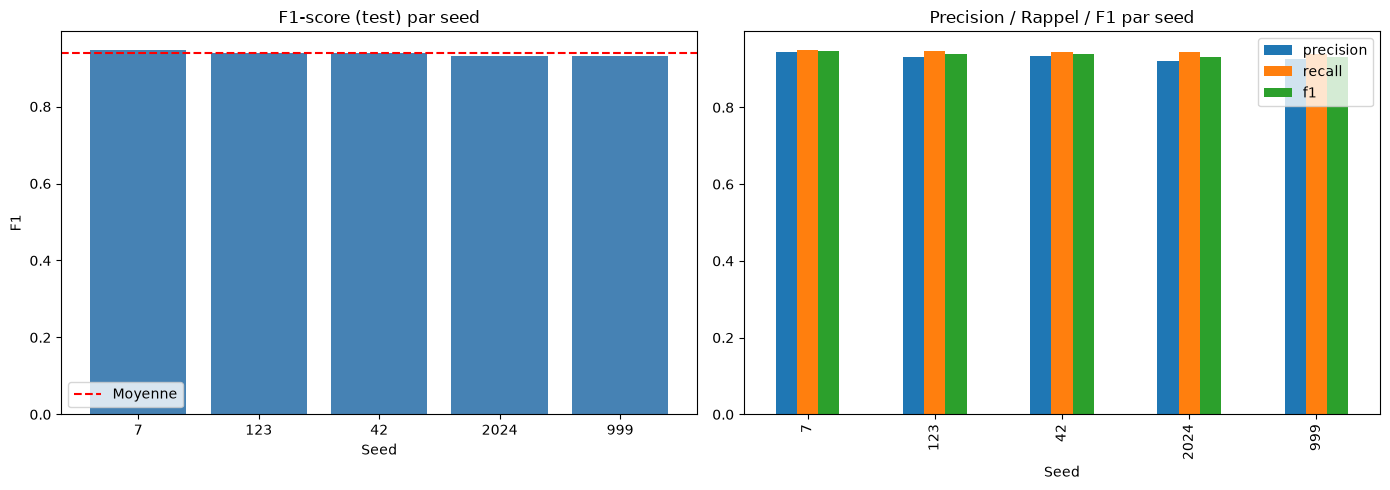

In [29]:
# Visualisation de la dispersion entre seeds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(benchmark_df["seed"].astype(str), benchmark_df["f1"], color="steelblue")
axes[0].axhline(benchmark_df["f1"].mean(), color="red", linestyle="--", label="Moyenne")
axes[0].set_title("F1-score (test) par seed")
axes[0].set_xlabel("Seed")
axes[0].set_ylabel("F1")
axes[0].legend()

benchmark_df.set_index("seed")[["precision", "recall", "f1"]].plot(
    kind="bar", ax=axes[1], title="Precision / Rappel / F1 par seed"
)
axes[1].set_xlabel("Seed")

plt.tight_layout()
plt.show()


Une visualisation/analyse complémentaire du benchmarking

La visualisation de la dispersion entre les seeds montre que les performances de **CamemBERT** restent globalement stables.

Le **F1 moyen** est de **0,9301**, avec **des valeurs comprises entre 0,9171 et 0,9387**.

**Le rappel** présente **une faible variabilité** entre les différentes exécutions, tandis que **la précision varie légèrement davantage**.

Ces résultats confirment l'intérêt d'utiliser plusieurs seeds afin d'évaluer la robustesse du fine-tuning face à l'aléatoire de l'entraînement.

### Décision : modèle retenu pour la suite du pipeline



In [ ]:

# DECISION - chargement du modele retenu

state = load_state()
best_seed_overall = int(benchmark_df.iloc[0]["seed"])
retained_seed = state["best_model_seed"]
assert retained_seed is not None and os.path.isdir(BEST_DIR), "Aucun modele sauvegarde dans BEST_DIR"

# NB : sur GPU, le modele est deplace sur model.device -> pour une inference manuelle
# (etape de fusion), envoyer aussi les tenseurs d'entree sur model.device.
model = AutoModelForTokenClassification.from_pretrained(BEST_DIR)
trainer = build_trainer(model, make_eval_args())

print(f"Modele retenu pour la suite du pipeline : seed={retained_seed} "
      f"(F1 test = {state['best_model_f1']:.4f})")
print(f"Performance a rapporter (moyenne des {len(benchmark_df)} seeds) : "
      f"{benchmark_df['f1'].mean():.4f} +/- {benchmark_df['f1'].std():.4f}")
if best_seed_overall != retained_seed:
    print(f"\nNote : le seed au meilleur F1 est {best_seed_overall}, mais son modele n'est pas sur disque "
          f"(resultat recopie du log). Le modele retenu est donc le seed {retained_seed}. "
          f"Si tu veux absolument le modele du seed {best_seed_overall}, supprime la cle "
          f"\"{best_seed_overall}\" de {STATE_PATH} et relance la boucle (~12 min pour ce seul seed).")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Modele retenu pour la suite du pipeline : seed=7 (F1 test = 0.9481)
Performance a rapporter (moyenne des 5 seeds) : 0.9379 +/- 0.0066


In [31]:
# Rapport detaille PAR CATEGORIE du modele retenu (a comparer au CRF et a la regex)

from seqeval.metrics import classification_report

pred_out = trainer.predict(dataset_tok["test"])
preds = np.argmax(pred_out.predictions, axis=2)
labels = pred_out.label_ids

true_predictions, true_labels = [], []
for pred_seq, label_seq in zip(preds, labels):
    true_predictions.append([id2label[p] for p, l in zip(pred_seq, label_seq) if l != -100])
    true_labels.append([id2label[l] for l in label_seq if l != -100])

print(classification_report(true_labels, true_predictions, zero_division=0))


                precision    recall  f1-score   support

       ADDRESS       0.95      0.97      0.96       554
       BANK_ID       0.94      0.96      0.95       333
    CREDENTIAL       0.93      0.97      0.95       221
CRYPTO_ADDRESS       1.00      1.00      1.00       119
          DATE       0.99      0.98      0.98       252
   DEMOGRAPHIC       0.96      0.96      0.96       427
    DIGITAL_ID       0.99      0.99      0.99       339
         EMAIL       0.99      1.00      1.00       107
     FINANCIAL       0.75      0.64      0.69       161
          MISC       0.89      0.95      0.92        80
          NAME       0.97      0.98      0.97       640
   NATIONAL_ID       0.66      0.61      0.64        67
           ORG       0.96      0.92      0.94       133
         PHONE       0.91      0.98      0.94       130

     micro avg       0.95      0.95      0.95      3563
     macro avg       0.92      0.92      0.92      3563
  weighted avg       0.94      0.95      0.95 

**Le modèle CamemBERT** obtient un F1 micro de 0,95 et un F1 pondéré de 0,95 sur le jeu de test. 

## Limites observées des trois approches (regex, CRF, CamemBERT)

| Approche | Limite observée | Chiffre |
|---|---|---|
| Regex | Ne détecte pas les PII non structurées | CREDENTIAL : F1 0,00 (221 faux négatifs) |
| Regex | Formats variables mal couverts | DATE 0,905 ; CRYPTO_ADDRESS rappel 0,832 |
| Regex | Fausses détections | PHONE précision 0,899 |
| CRF | Rappel faible sur plusieurs catégories | CRYPTO_ADDRESS 0,55 ; FINANCIAL 0,56 ; CREDENTIAL 0,70 |
| CamemBERT | Faible sur certaines catégories à petit effectif | NATIONAL_ID 0,64 (67 entités) ; FINANCIAL 0,69 |

**Recap :** chacun a des limites, donc j'ai suivi la littérature qui recommande de les combiner.


## Pipeline hybride final : 

**Hypothèse :** les PII structurées se détectent par règles, les PII contextuelles par un modèle. Cette hypothèse est appuyée par la littérature (RECAP, « Mind the Gap »).

**Choix de la méthode par catégorie :** certaines catégories sont confiées aux Regex, les autres à CamemBERT, puis les résultats sont fusionnés.

**pourquoi le CRF n'est pas dans l'hybride?**
le CRF a un F1 micro de 0,90 contre 0,95 pour CamemBERT, et il est en dessous de lui sur presque toutes les catégories. CamemBERT le remplace donc comme composante contextuelle. Précise aussi que le CRF est évalué par token, ce qui limite la comparaison directe.



In [32]:
# PIPELINE HYBRIDE : regex (categories structurees) + CamemBERT (contextuelles)

import torch

REGEX_AUTHORITATIVE = {"EMAIL", "PHONE", "BANK_ID", "NATIONAL_ID"}
MODEL_AUTHORITATIVE = {
    "DATE", "CRYPTO_ADDRESS", "CREDENTIAL",
    "ADDRESS", "DEMOGRAPHIC", "DIGITAL_ID", "NAME", "ORG", "FINANCIAL", "MISC",
}

# Le modele et le tokenizer du seed retenu (cf. cellule "DECISION" plus haut)
hybrid_model = trainer.model
hybrid_model.eval()
device = hybrid_model.device


def get_model_entities(text):
    """Fait tourner CamemBERT sur un texte brut et reconstruit les spans
    d'entites (start/end/label caracteres) a partir des tags B-/I- predits,
    via l'offset_mapping du tokenizer."""
    inputs = tokenizer(text, return_offsets_mapping=True, truncation=True,
                        max_length=128, return_tensors="pt")
    offsets = inputs.pop("offset_mapping")[0].tolist()
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        logits = hybrid_model(**inputs).logits
    pred_ids = torch.argmax(logits, dim=2)[0].tolist()
    pred_tags = [id2label[i] for i in pred_ids]

    entities = []
    current_label, current_start, current_end = None, None, None
    for (start, end), tag in zip(offsets, pred_tags):
        if start == end:  # token special ([CLS]/[SEP]/padding)
            continue
        if tag == "O":
            if current_label is not None:
                entities.append({"start": current_start, "end": current_end,
                                  "label": current_label, "validated": False})
                current_label = None
            continue
        prefix, label = tag.split("-", 1)
        if prefix == "B" or label != current_label:
            if current_label is not None:
                entities.append({"start": current_start, "end": current_end,
                                  "label": current_label, "validated": False})
            current_label, current_start, current_end = label, start, end
        else:  # I- qui continue la meme entite
            current_end = end
    if current_label is not None:
        entities.append({"start": current_start, "end": current_end,
                          "label": current_label, "validated": False})
    return entities


def hybrid_detect(text):
    """Fusionne regex_detect() et get_model_entities(), en ne gardant que la
    source autoritative par categorie (cf. table de routage)."""
    regex_entities = [e for e in regex_detect(text) if e["label"] in REGEX_AUTHORITATIVE]
    model_entities = [e for e in get_model_entities(text) if e["label"] in MODEL_AUTHORITATIVE]

    all_entities = regex_entities + model_entities
    return resolve_overlaps(all_entities)  # reutilise la fonction deja definie (baseline regex)


# --- Test rapide sur un exemple du test set ---
sample_text = test_df.iloc[0]["unmasked_text"]
print("Texte :", sample_text[:200], "...\n")
print("Entites hybrides detectees :")
for e in hybrid_detect(sample_text):
    label = e["label"]
    span_text = sample_text[e["start"]:e["end"]]
    print(f"  [{label:15s}] {span_text!r}")


Texte : En ce qui concerne les politiques de l'enseignement supérieur, la sécurité en ligne est cruciale. Par conséquent, il est primordial de protéger correctement les identifiants des utilisateurs (3kXQrHpi ...

Entites hybrides detectees :
  [CREDENTIAL     ] '(3kXQrHpiCGtD'
  [CREDENTIAL     ] '2163'
  [DIGITAL_ID     ] '56.70.213.166'
  [DIGITAL_ID     ] 'c6bc:9be3:bbbb:4190:e6e0:a444:54f1:4760)'
  [PHONE          ] '(34-593993-480217-7'


### Evaluation du pipeline hybride sur le test set complet

Meme logique que `evaluate_regex_by_category`, mais categorie par categorie sur
`hybrid_detect()`, pour produire le tableau final a comparer aux 3 baselines
(regex seule / CRF / CamemBERT seul).

In [33]:
def evaluate_hybrid_by_category(df_subset, categories):
    results = {}
    for cat in categories:
        tp = fp = fn = 0
        for _, row in df_subset.iterrows():
            text = row["unmasked_text"]
            reference = [e for e in row["entities_reduced"] if e["label"] == cat]
            predicted = [e for e in hybrid_detect(text) if e["label"] == cat]

            matched_refs = set()
            for p in predicted:
                match = None
                for i, r in enumerate(reference):
                    if i not in matched_refs and p["start"] < r["end"] and p["end"] > r["start"]:
                        match = i
                        break
                if match is not None:
                    tp += 1
                    matched_refs.add(match)
                else:
                    fp += 1
            fn += len(reference) - len(matched_refs)

        precision = tp / (tp + fp) if (tp + fp) else 0
        recall = tp / (tp + fn) if (tp + fn) else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
        results[cat] = {"precision": precision, "recall": recall, "f1": f1,
                         "tp": tp, "fp": fp, "fn": fn}
    return pd.DataFrame(results).T


ALL_CATEGORIES = sorted(REGEX_AUTHORITATIVE | MODEL_AUTHORITATIVE)
hybrid_results = evaluate_hybrid_by_category(test_df, ALL_CATEGORIES)
print("=== Pipeline HYBRIDE : resultats par categorie ===")
print(hybrid_results.round(3))


=== Pipeline HYBRIDE : resultats par categorie ===
                precision  recall     f1     tp    fp    fn
ADDRESS             0.966   0.986  0.976  547.0  19.0   8.0
BANK_ID             0.957   0.931  0.944  311.0  14.0  23.0
CREDENTIAL          0.965   0.986  0.975  218.0   8.0   3.0
CRYPTO_ADDRESS      1.000   1.000  1.000  119.0   0.0   0.0
DATE                0.996   0.984  0.990  248.0   1.0   4.0
DEMOGRAPHIC         0.970   0.970  0.970  414.0  13.0  13.0
DIGITAL_ID          0.997   0.933  0.964  318.0   1.0  23.0
EMAIL               0.991   1.000  0.995  107.0   1.0   0.0
FINANCIAL           0.970   0.801  0.878  129.0   4.0  32.0
MISC                0.988   1.000  0.994   80.0   1.0   0.0
NAME                0.972   0.986  0.979  631.0  18.0   9.0
NATIONAL_ID         0.985   1.000  0.993   67.0   1.0   0.0
ORG                 0.976   0.932  0.954  124.0   3.0   9.0
PHONE               0.899   0.962  0.929  125.0  14.0   5.0


### Résultats

Pour évaluer les performances, j’ai utilisé la **précision, le rappel et le F1-score**, avec une analyse par catégorie.

Globalement, l’approche hybride donne de **très bons résultats**. Par exemple, on obtient un F1-score de **0,995 pour EMAIL**, **0,979 pour NAME** et **0,990 pour DATE**. Pour **CRYPTO_ADDRESS**, le F1-score atteint **1** sur l’échantillon évalué.

Certaines catégories restent cependant plus difficiles. Pour **FINANCIAL**, le F1-score est de **0,878**, notamment à cause d’un rappel de **0,801**.

Pour **PHONE**, le rappel est élevé, mais la précision est plus faible, ce qui indique davantage de **fausses détections**.



## Synthèse comparative des quatre approches 

,Regex (permissif),"CRF (par token, B-)",CamemBERT (seqeval),Hybride (permissif)
ADDRESS,–,0.850,0.960,0.976
BANK_ID,0.944,0.860,0.950,0.944
CREDENTIAL,0.000,0.790,0.950,0.975
CRYPTO_ADDRESS,0.908,0.650,1.000,1.000
DATE,0.905,0.880,0.980,0.990
DEMOGRAPHIC,–,0.930,0.960,0.970
DIGITAL_ID,–,0.820,0.990,0.964
EMAIL,0.995,1.000,1.000,0.995
FINANCIAL,–,0.700,0.690,0.878
MISC,–,0.810,0.920,0.994


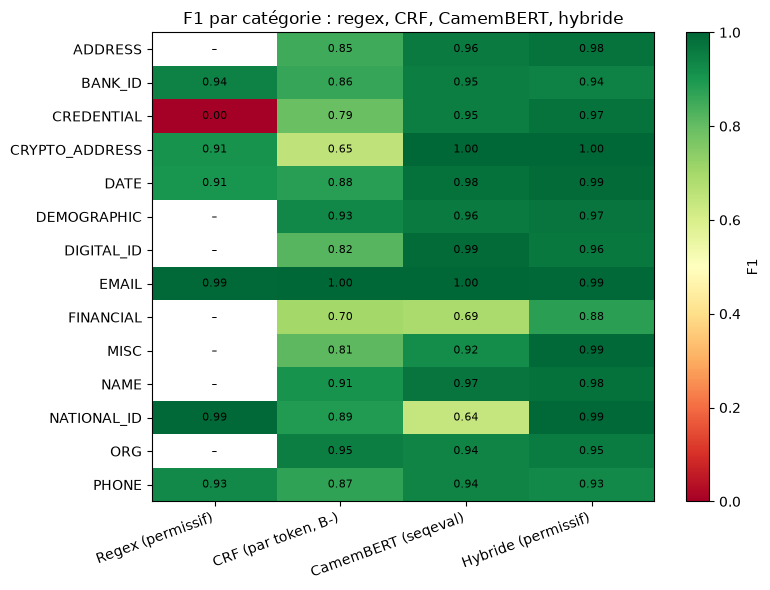

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from seqeval.metrics import classification_report as seq_report
from sklearn_crfsuite import metrics as crf_metrics

CATS = sorted(REGEX_AUTHORITATIVE | MODEL_AUTHORITATIVE)   # les 14 catégories

# 1) Regex (match permissif) : tableau de la cellule 43, F1 par catégorie
regex_f1 = results_df["f1"].astype(float)

# 2) CRF (par token, étiquettes B- uniquement) : rapport de la cellule 47
crf_rep = crf_metrics.flat_classification_report(
    y_test_crf, y_pred_crf, labels=labels_present,
    output_dict=True, zero_division=0)
crf_f1 = pd.Series({c: crf_rep[f"B-{c}"]["f1-score"]
                    for c in CATS if f"B-{c}" in crf_rep})

# 3) CamemBERT (seqeval, match strict d'entité) : rapport de la cellule 64
cam_rep = seq_report(true_labels, true_predictions,
                     output_dict=True, zero_division=0)
cam_f1 = pd.Series({c: cam_rep[c]["f1-score"] for c in CATS if c in cam_rep})

# 4) Hybride (match permissif) : tableau de la cellule 69
hyb_f1 = hybrid_results["f1"].astype(float)

# Assemblage : NaN = catégorie non traitée par la regex
bench = pd.DataFrame({
    "Regex (permissif)":     regex_f1,
    "CRF (par token, B-)":   crf_f1,
    "CamemBERT (seqeval)":   cam_f1,
    "Hybride (permissif)":   hyb_f1,
}).reindex(CATS)

# --- Affichage du tableau avec mise en couleur ---
display(bench.style
        .format("{:.3f}", na_rep="–")
        .background_gradient(cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("F1 par catégorie (métriques non identiques, voir note)"))

# --- Heatmap ---
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(bench.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(bench.shape[1]))
ax.set_xticklabels(bench.columns, rotation=20, ha="right")
ax.set_yticks(range(bench.shape[0]))
ax.set_yticklabels(bench.index)
for i in range(bench.shape[0]):
    for j in range(bench.shape[1]):
        v = bench.values[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:.2f}",
                ha="center", va="center", fontsize=8)
ax.set_title("F1 par catégorie : regex, CRF, CamemBERT, hybride")
plt.colorbar(im, ax=ax, label="F1")
plt.tight_layout()
plt.show()

# --- Génère le tableau en Markdown (à copier dans une cellule Markdown) ---
def to_md(df):
    cols = ["Catégorie"] + list(df.columns)
    lines = ["| " + " | ".join(cols) + " |",
             "|" + "---|" * len(cols)]
    for cat, row in df.iterrows():
        vals = ["–" if pd.isna(v) else f"{v:.3f}".replace(".", ",") for v in row]
        lines.append("| " + " | ".join([cat] + vals) + " |")
    return "\n".join(lines)

print(to_md(bench))


**Globalement, ces résultats montrent que l’approche hybride permet de détecter efficacement les données personnelles et constitue donc une solution intéressante pour atteindre l’objectif du projet : détecter puis anonymiser automatiquement les informations sensibles dans les textes français.**

l’écart entre CamemBERT seul et le modèle hybride est globalement pertinent

le gain global de 4,9 % est principalement porté par certaines catégories difficiles

## Reconstruction (nettoyage des spans avant anonymisation)

Cette étape constitue **un contrôle qualité avant l'anonymisation.** 

Je reconstruis le texte brut de chaque entité à partir de ses **positions start et end**, afin de vérifier que les **offsets sont correctement alignés avec le texte original**. 

Je vérifie également qu'il ne reste aucun chevauchement entre les entités après la résolution des overlaps. 



In [35]:
def reconstruct_entity_text(text, entities):
    """Ajoute le texte brut de chaque entite, trie par position, et
    verifie l'absence de chevauchement residuel."""
    enriched = []
    for e in sorted(entities, key=lambda x: x["start"]):
        enriched.append({**e, "raw_text": text[e["start"]:e["end"]]})
    for i in range(1, len(enriched)):
        if enriched[i]["start"] < enriched[i - 1]["end"]:
            print("ATTENTION chevauchement residuel :", enriched[i - 1], enriched[i])
    return enriched


# --- CONTROLE sur 5 exemples ---
print("=== Verification de la reconstruction sur 5 exemples ===\n")
for _, row in test_predictions.head(5).iterrows():
    enriched = reconstruct_entity_text(row["text"], row["entities"])
    print(f"Texte : {row['text'][:80]}...")
    for e in enriched:
        label = e["label"]
        raw = e["raw_text"]
        print(f"   [{label:15s}] {raw!r}")
    print()


=== Verification de la reconstruction sur 5 exemples ===

Texte : En ce qui concerne les politiques de l'enseignement supérieur, la sécurité en li...
   [CREDENTIAL     ] '(3kXQrHpiCGtD'
   [CREDENTIAL     ] '2163'
   [DIGITAL_ID     ] '56.70.213.166'
   [DIGITAL_ID     ] 'c6bc:9be3:bbbb:4190:e6e0:a444:54f1:4760)'
   [PHONE          ] '(34-593993-480217-7'

Texte : Cher Ms., nous avons une opportunité de tutorat pour vous à Douglasberg. Un dipl...
   [NAME           ] 'Ms.'
   [ADDRESS        ] 'Douglasberg'
   [ORG            ] 'Directives'
   [EMAIL          ] 'Lonnie39@hotmail.com'

Texte : J'espère que ces informations concernant le compte Home Loan Account vous seront...
   [CREDENTIAL     ] 'Home Loan Account'
   [ADDRESS        ] '64082'
   [PHONE          ] '88-670675-983245-5'

Texte : La communication sécurisée des informations sur les patients est essentielle. Ve...
   [DIGITAL_ID     ] 'f9:09:0a:92:b2:93'
   [NAME           ] 'Dr.'
   [NAME           ] 'Ryan'

Texte : Orie,


Sur les cinq exemples inspectés, aucune alerte de chevauchement n'est apparue et les spans extraits semblent correctement délimités. 

Cette étape valide donc la cohérence des annotations avant de procéder à l'anonymisation


##  Anonymisation


In [36]:
def anonymize_mask(text, entities):
    """Remplace chaque entite par [LABEL]. Traite les spans du dernier au
    premier pour ne pas decaler les indices des spans precedents."""
    result = text
    for e in sorted(entities, key=lambda x: x["start"], reverse=True):
        result = result[:e["start"]] + f"[{e['label']}]" + result[e["end"]:]
    return result


def anonymize_pseudonymize(text, entities):
    """Remplace chaque entite par un pseudonyme stable : meme (label, valeur
    source) -> meme pseudonyme, y compris pour des repetitions dans le meme
    texte. Garde le texte lisible/coherent."""
    seen = {}
    result = text
    for e in sorted(entities, key=lambda x: x["start"], reverse=True):
        raw = text[e["start"]:e["end"]]
        key = (e["label"], raw)
        if key not in seen:
            idx = len([k for k in seen if k[0] == e["label"]]) + 1
            seen[key] = f"{e['label']}_{idx}"
        result = result[:e["start"]] + seen[key] + result[e["end"]:]
    return result


# --- DEMONSTRATION QUALITATIVE : original vs anonymise, cote a cote ---
print("=== Demonstration sur 5 exemples (masquage) ===\n")
for _, row in test_predictions.head(5).iterrows():
    masked = anonymize_mask(row["text"], row["entities"])
    print("ORIGINAL   :", row["text"])
    print("ANONYMISE  :", masked)
    print("-" * 100)

print("\n=== Demonstration sur 2 exemples (pseudonymisation) ===\n")
for _, row in test_predictions.head(2).iterrows():
    pseudo = anonymize_pseudonymize(row["text"], row["entities"])
    print("ORIGINAL      :", row["text"])
    print("PSEUDONYMISE  :", pseudo)
    print("-" * 100)


=== Demonstration sur 5 exemples (masquage) ===

ORIGINAL   : En ce qui concerne les politiques de l'enseignement supérieur, la sécurité en ligne est cruciale. Par conséquent, il est primordial de protéger correctement les identifiants des utilisateurs (3kXQrHpiCGtD, 2163), les adresses IP (56.70.213.166, c6bc:9be3:bbbb:4190:e6e0:a444:54f1:4760) et les IMEI des téléphones (34-593993-480217-7).
ANONYMISE  : En ce qui concerne les politiques de l'enseignement supérieur, la sécurité en ligne est cruciale. Par conséquent, il est primordial de protéger correctement les identifiants des utilisateurs [CREDENTIAL], [CREDENTIAL]), les adresses IP ([DIGITAL_ID], [DIGITAL_ID] et les IMEI des téléphones [PHONE]).
----------------------------------------------------------------------------------------------------
ORIGINAL   : Cher Ms., nous avons une opportunité de tutorat pour vous à Douglasberg. Un diplômé fraîchement sorti dans votre domaine professionnel de Directives cherche à développer des c

Cette étape consiste à anonymiser les entités détectées. J'ai implémenté deux stratégies: 

La première est **le masquage**, où chaque entité est remplacée par sa catégorie, par exemple [EMAIL].

La seconde est **la pseudonymisation**, où chaque valeur est remplacée par un pseudonyme stable comme EMAIL_1. Lors du remplacement, je traite les entités de droite à gauche afin de ne pas modifier les indices des entités précédentes. 
 
Enfin, je réalise **un contrôle visuel** entre le texte original et le texte anonymisé afin de vérifier qu'il n'y a pas de mots coupés, de chevauchements ou de corruption du texte.

Je n’ai pas utilisé d’IA générative. J’ai privilégié une approche basée sur des règles, afin que les données personnelles soient traitées localement et ne soient pas envoyées à un service d’IA externe. C’est un choix important dans un projet de protection des données, car l’utilisation d’un service externe pourrait impliquer la transmission d’informations sensibles.

## Analyse critique et limites

Ces résultats montrent que les performances dépendent fortement de la nature des données personnelles.

Les informations ayant une structure régulière peuvent être efficacement détectées par des règles déterministes, tandis que les catégories dépendant davantage du contexte peuvent bénéficier du modèle CamemBERT.

Plusieurs limites doivent cependant être prises en compte.

Premièrement, le dataset présente un déséquilibre entre les catégories, ce qui peut rendre certaines catégories plus difficiles à apprendre.

Deuxièmement, le regroupement des 56 catégories en 14 catégories simplifie l'apprentissage mais réduit la précision sémantique.

Une limite du modèle concerne les textes dépassant 128 tokens, qui peuvent être tronqués. Une amélioration future consisterait à utiliser une approche par fenêtres glissantes avec chevauchement afin de traiter les textes longs

Comme **perspectives** , je pourrais améliorer les règles Regex et tester d’autres modèles de langage.







## Conclusion


Pour conclure, dans un contexte où la confidentialité des données est un enjeu important, l’anonymisation permet de protéger les informations personnelles tout en facilitant leur utilisation. 

Mon projet montre qu’une approche hybride combinant Regex et CamemBERT peut permettre de détecter automatiquement ces données, puis de les anonymiser de manière locale et contrôlée



## Cadre réglementaire - AI Act

L’utilisation de systèmes d’intelligence artificielle impliquant des données personnelles nécessite de respecter à la fois les réglementations relatives à la protection des données (comme le RGPD) et celles encadrant les systèmes d’IA (AI Act).

Dans ce contexte, des techniques telles que la détection et l’anonymisation des données personnelles permettent de réduire les risques liés à leur traitement, à condition que l’anonymisation soit effective et irréversible.

Par ailleurs, ces pratiques s’inscrivent également dans des cadres réglementaires nationaux. En Tunisie, la loi organique n°63-2004, supervisée par l’INPDP, encadre la collecte et le traitement des données à caractère personnel, renforçant l’importance de méthodes garantissant leur protection.



## Références principales

Rajgarhia et al. (2025), RECAP — distinction entre PII structurées et PII sémantiquement variables.

Lison & Pilán (2021, 2022), travaux sur le Text Anonymization Benchmark.

Mind the Gap (2025) — analyse des performances selon le degré de rigidité des formats PII.

Zaratiana et al. (2026), GLiNER2-PII — détection de PII avec un modèle générique adaptable.

Étude Scientific Reports (2025) — approche hybride règles + ML + NER pour l'anonymisation de documents financiers.

OpenAI, ChatGPT (2026) — utilisé comme outil d’assistance pour la recherche documentaire, la compréhension de concepts et l’identification de pistes bibliographiques ; les références scientifiques ont été vérifiées à partir de leurs sources originales.